# 01 — Sanity: is the cluster serving, and through the gateway?

**Run this first.** Nothing after it means anything if this fails: a load
test against a half-up fleet measures the half that is up.

| | |
|---|---|
| **Objective** | Prove the cluster serves a real completion, and that it goes *through* our control plane rather than past it |
| **Falsified by** | `orch_requests_total` not moving, or any pool not answering |
| **Produces** | `../reports/01-sanity.pdf` |
| **Next** | `02-capacity` — what binds, and at what load |

Each section states its question, measures it, draws it, and ends with a
`>>` conclusion. Run top to bottom; it takes about two minutes.

**Needs** the tunnel (`make ssh`). Latency here includes your round-trip to
the box, so treat it as shape. `make load` runs on the box for real numbers.


In [1]:
import sys
sys.path.insert(0, '..')   # utils.py and slos.py live in benchmarking/

from utils import (Cluster, Report, sum_by_name, filler, percentile,
                   grafana_dashboard, grafana_explore, REPORTS)
from slos import table_rows, target_sessions

cluster = Cluster()   # gateway :8080, prefill :30800, decode :30801
report  = Report('Dodona 01 — cluster sanity', 'go / no-go, no load')

report.objective(
    'Does the cluster serve a real completion, and does it go THROUGH the '
    'control plane rather than past it?',
    falsified_by='orch_requests_total not moving, or a pool not answering')

report.heading('The promises everything later is scored against')
report.table(['SLO', 'target', 'direction'], table_rows(),
             note='From benchmarking/slos.py. The session target is derived in 02.')
if target_sessions() is None:
    report.text('Concurrency target not measured yet — run 02-capacity.')


## 1. Is anything listening?

**Question.** Do the gateway and both pools answer?

A `FAIL` on a pool means it never came up — not that it is idle. Everything
below reads from these endpoints, so a failure here invalidates the rest.


In [2]:
report.heading('1. Is anything listening?')
up = cluster.endpoints()
for name, ok in up.items():
    report.verdict(ok, name)

if all(up.values()):
    report.conclusion('All four endpoints answer, so the readings below are real.')
else:
    down = [n for n, ok in up.items() if not ok]
    report.conclusion(f'DOWN: {", ".join(down)}. Open the tunnel (make ssh) and '
                      'check `sudo k3s kubectl get pods` before reading further.')



1. Is anything listening?


  PASS  gateway /metrics
  PASS  gateway /v1/models
  PASS  prefill /metrics
  PASS  decode /metrics

  >> All four endpoints answer, so the readings below are real.



## 2. Which pool does which job?

**Question.** Is the prefill/decode split real, or are both pods doing the
same thing?

The gateway sends prefill its leg with `max_tokens=1` — enough to build the
prompt's KV, not to answer. So the split is working if **prefill's generation
count is near zero while decode's is not**.

The chart is log-scaled: the two quantities differ by orders of magnitude.



2. Which pool does which job?
  PASS  gateway advertises: Qwen/Qwen2.5-7B-Instruct-AWQ


  pool     running  waiting  prompt tok  gen tok
  -------  -------  -------  ----------  -------
  prefill        0        0     845,264      298
  decode         0        0     835,108      590
  -- prompt tok of 0 on a pool means nothing was ever routed to it.


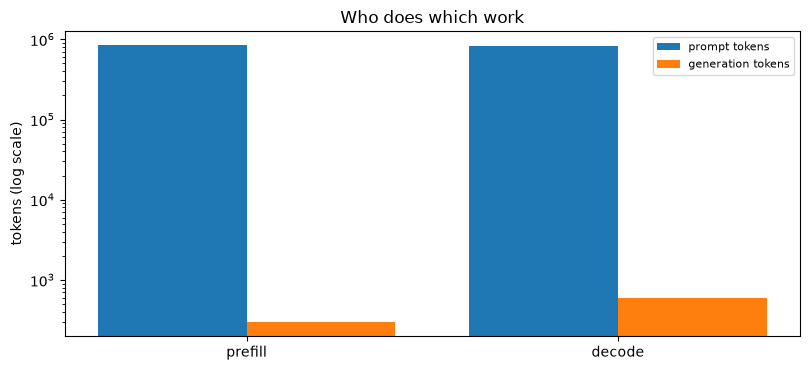

  how to read it: prefill should be high on prompt and flat on generation
  FAIL  prefill emits 49.67 tokens per request (max_tokens=1 means ~1.0)

  >> Prefill emitted 49.67 tokens per request, not ~1.0. A max_tokens=1 leg cannot do that, so both legs are sending the full request — check LAB_SPLIT and VLLMWorker.enqueue.



In [3]:
report.heading('2. Which pool does which job?')
model = cluster.served_model()
report.verdict(bool(model), f'gateway advertises: {model}')

pre_m, dec_m = cluster.pool_metrics('prefill'), cluster.pool_metrics('decode')
prompt = [sum_by_name(m, 'vllm:prompt_tokens_total')     for m in (pre_m, dec_m)]
gen    = [sum_by_name(m, 'vllm:generation_tokens_total') for m in (pre_m, dec_m)]

report.table(['pool', 'running', 'waiting', 'prompt tok', 'gen tok'], [
    ['prefill', int(sum_by_name(pre_m, 'vllm:num_requests_running')),
     int(sum_by_name(pre_m, 'vllm:num_requests_waiting')),
     f'{prompt[0]:,.0f}', f'{gen[0]:,.0f}'],
    ['decode',  int(sum_by_name(dec_m, 'vllm:num_requests_running')),
     int(sum_by_name(dec_m, 'vllm:num_requests_waiting')),
     f'{prompt[1]:,.0f}', f'{gen[1]:,.0f}'],
], note='prompt tok of 0 on a pool means nothing was ever routed to it.')

report.bar('Who does which work', ['prefill', 'decode'],
           {'prompt tokens': prompt, 'generation tokens': gen},
           ylabel='tokens (log scale)', log=True,
           note='prefill should be high on prompt and flat on generation')

# Prefill emits exactly ONE token per request; decode emits up to max_tokens.
# These sanity requests use max_tokens=8, so the expected ratio is about 1:8.
# A threshold of 1:10 would be stricter than the design and fail a healthy
# fleet — it did, on 162 against 1,247.
# The invariant is NOT prefill-vs-decode: that ratio depends on how long the
# answers happen to be. "Reply with ok" generates ~2 tokens, so a healthy split
# reads 1:2 and a chattier prompt reads 1:200. What is fixed by design is that
# prefill emits exactly ONE token per request.
served = sum_by_name(cluster.gateway_metrics(), 'orch_requests_total')
per_req = gen[0] / served if served else 0
report.verdict(sum(prompt) == 0 or per_req < 1.5,
               f'prefill emits {per_req:.2f} tokens per request (max_tokens=1 means ~1.0)')

if sum(prompt) == 0:
    report.conclusion('No traffic yet — these counters reset when the pods restarted.')
elif per_req < 1.5:
    report.conclusion(
        f'The split is real: prefill emitted {gen[0]:,.0f} tokens over {served:,.0f} '
        f'requests — {per_req:.2f} each, which is the max_tokens=1 leg doing prompt '
        f"work only, against decode's {gen[1]:,.0f}. But both pools show the same "
        'prompt-token count, so decode is still paying to process the prompt — '
        'section 5 measures why.')
else:
    report.conclusion(
        f'Prefill emitted {per_req:.2f} tokens per request, not ~1.0. A max_tokens=1 '
        'leg cannot do that, so both legs are sending the full request — check '
        'LAB_SPLIT and VLLMWorker.enqueue.')


## 3. How much room does one pod actually have?

**Question.** What sets concurrency — and is it small enough that a policy
has something to decide?

This is the number every later claim divides by, and the easiest one to get
wrong. The **card** has 64 GiB of KV; a **12 GiB slice** has about 4.3 after
weights and CUDA graphs. Quoting the card's figure for a slice overstates
concurrency by roughly 15x.

Fill the two constants from your own pods:

```bash
make logs | grep -E 'Available KV cache memory|Maximum concurrency'
```



3. How much room does one pod have?
  quantity                       value  where it comes from                    
  -------------------------  ---------  ---------------------------------------
  slice x util               10.80 GiB  HAMi gpumem x --gpu-memory-utilization 
  weights                     5.20 GiB  Qwen2.5-7B AWQ int4, embeddings in fp16
  activations + CUDA graphs   1.50 GiB  budget minus weights minus KV          
  KV cache                    4.10 GiB  pod log: Available KV cache memory     
  seqs per pod at 16k              4.7  pod log: Maximum concurrency           
  decode pool                      4.7  seqs per pod x replicas                


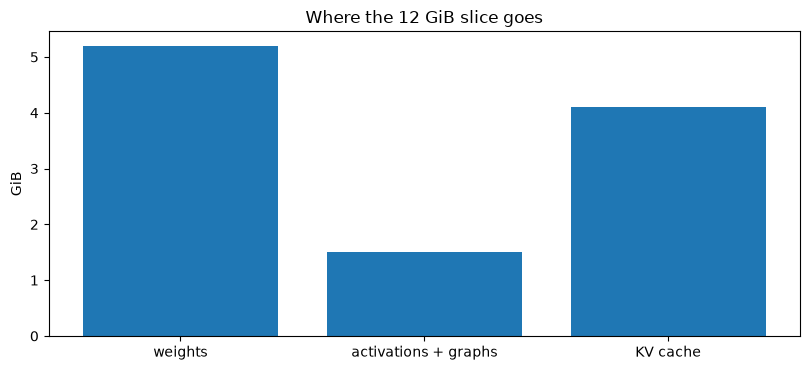

  how to read it: only the third bar holds sequences
  PASS  a pool of 4.7 is small enough for KV to bind

  >> KV gets 4.10 of 10.80 usable GiB, which buys 4.7 full-length sequences per pod and a pool of 4.7. That is the scarcity the admission experiments need. The whole card would suggest 73.5 — do not quote that for a slice.



Report(title='Dodona 01 — cluster sanity', subtitle='go / no-go, no load', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='Does the cluster serve a real completion, and does it go THROUGH the control plane rather than past it?', note=''), _Block(kind='text', payload='Falsified by: orch_requests_total not moving, or a pool not answering', note=''), _Block(kind='heading', payload='The promises everything later is scored against', note=''), _Block(kind='table', payload=(['SLO', 'target', 'direction'], [['TTFT p95', '1.5s', 'max'], ['turn p95', '30s', 'max'], ['preemptions', '0', 'max'], ['shed rate at target load', '0.05', 'max'], ['concurrent sessions', 'derived in 02', 'min']]), note='From benchmarking/slos.py. The session target is derived in 02.'), _Block(kind='text', payload='Concurrency target not measured yet — run 02-capacity.', note=''), _Block(kind='heading', payload='1. Is anything listening?', note=''), _Block(kind='verdict', payload=

In [4]:
# FROM THE POD LOG — replace with what your pods report.
KV_GIB_PER_POD  = 4.10   # 'Available KV cache memory: X GiB'
SEQ_PER_POD     = 4.7    # 'Maximum concurrency for 16,384 tokens: Xx'
DECODE_REPLICAS = 1      # KEDA scales this to 2 under load
SLICE_GIB, UTIL, WEIGHTS_GIB = 12.0, 0.90, 5.2

report.heading('3. How much room does one pod have?')
overhead = SLICE_GIB * UTIL - WEIGHTS_GIB - KV_GIB_PER_POD
pool = SEQ_PER_POD * DECODE_REPLICAS

report.table(['quantity', 'value', 'where it comes from'], [
    ['slice x util', f'{SLICE_GIB * UTIL:.2f} GiB', 'HAMi gpumem x --gpu-memory-utilization'],
    ['weights', f'{WEIGHTS_GIB:.2f} GiB', 'Qwen2.5-7B AWQ int4, embeddings in fp16'],
    ['activations + CUDA graphs', f'{overhead:.2f} GiB', 'budget minus weights minus KV'],
    ['KV cache', f'{KV_GIB_PER_POD:.2f} GiB', 'pod log: Available KV cache memory'],
    ['seqs per pod at 16k', f'{SEQ_PER_POD:.1f}', 'pod log: Maximum concurrency'],
    ['decode pool', f'{pool:.1f}', 'seqs per pod x replicas'],
])
report.bar('Where the 12 GiB slice goes',
           ['weights', 'activations + graphs', 'KV cache'],
           {'GiB': [WEIGHTS_GIB, max(overhead, 0), KV_GIB_PER_POD]}, ylabel='GiB',
           note='only the third bar holds sequences')
report.verdict(pool < 20, f'a pool of {pool:.1f} is small enough for KV to bind')
report.conclusion(
    f'KV gets {KV_GIB_PER_POD:.2f} of {SLICE_GIB * UTIL:.2f} usable GiB, which buys '
    f'{SEQ_PER_POD:.1f} full-length sequences per pod and a pool of {pool:.1f}. '
    'That is the scarcity the admission experiments need. The whole card would '
    'suggest 73.5 — do not quote that for a slice.')


## 4. Does a request actually go through the gateway?

**Question.** Is our control plane in the path, or is traffic reaching the
pods directly?

This decides whether anything we built is real. `orch_requests_total` only
moves if the request passed our gateway — a completion that reached a pod
directly leaves it untouched, and from the outside the two are identical.


In [5]:
report.heading('4. Does a request go through the gateway?')
before = sum_by_name(cluster.gateway_metrics(), 'orch_requests_total')
answer = cluster.chat('Reply with the single word: ok', max_tokens=8)
after  = sum_by_name(cluster.gateway_metrics(), 'orch_requests_total')

report.verdict(after > before, f'orch_requests_total {before:.0f} -> {after:.0f}')
report.verdict('_error' not in answer, f"completion in {answer['_latency_s']}s")

if '_error' in answer:
    report.text(f"{answer['_error']}: {str(answer.get('_body',''))[:200]}")
    report.conclusion('The gateway answered, but refused the request. The refusal '
                      'reason above is a gateway decision, not a GPU limit.')
else:
    said = ((answer.get('choices') or [{}])[0].get('message') or {}).get('content')
    report.table(['field', 'value'], [
        ['content', repr(said)], ['via', answer.get('via')],
        ['latency', f"{answer['_latency_s']}s (tunnel included)"]])
    report.conclusion(
        f'The counter moved and the model answered {said!r}. Guardrails, '
        'admission, placement and the hop all ran. via=local means our cluster '
        'served it rather than bursting to a provider.')



4. Does a request go through the gateway?


  PASS  orch_requests_total 6 -> 7
  FAIL  completion in 0.251s
  HTTP 503: {"error": {"type": "server_is_overloaded", "message": "worker unreachable"}, "via": "local"}

  >> The gateway answered, but refused the request. The refusal reason above is a gateway decision, not a GPU limit.



## 5. Did any KV actually move between the pods?

**Question.** Is the prefill→decode hop moving bytes, or recording that it
would have?

The response carries a `kv_hop` record, but a record is not a transfer. vLLM
counts the real thing itself:

| counter | means |
|---|---|
| `external_prefix_cache_queries_total` | the connector was asked |
| `external_prefix_cache_hits_total` | it returned blocks |
| `prompt_tokens_by_source{external_kv_transfer}` | tokens that arrived as KV instead of being computed |

**queries > 0 with hits == 0** is unambiguous: the connector is wired up,
is being consulted, and is moving nothing.



5. Did any KV actually move?
  FAIL  the router RECORDED a hop
  where decode's prompt KV came from  tokens
  ----------------------------------  ------
  computed from scratch                    0
  decode's own prefix cache                0
  the connector (a real hop)               0
  -- decode is SENT the whole prompt either way, so prompt_tokens_total never moves — only this split does.
  connector counter         value
  ------------------------  -----
  times asked                   0
  times it returned blocks      0


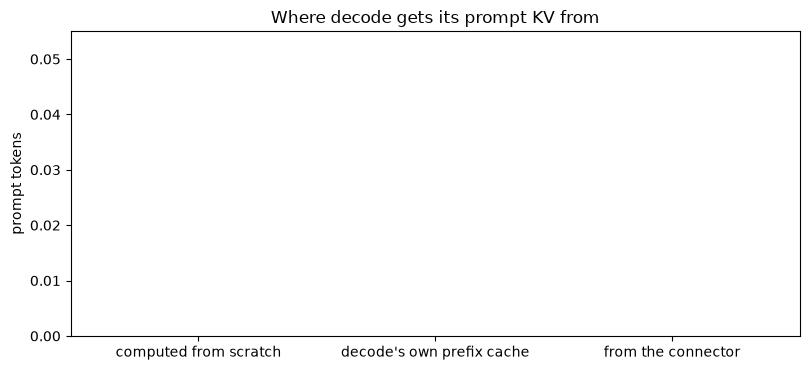

  how to read it: only the third bar is a KV hop; the second is vLLM caching its own repeats
  FAIL  the connector has delivered at least one block

  >> The connector was never consulted — check --kv-transfer-config on both pools.



In [6]:
report.heading('5. Did any KV actually move?')
hop = answer.get('kv_hop') if isinstance(answer, dict) else None
report.verdict(bool(hop), 'the router RECORDED a hop')
if hop:
    report.table(['field', 'value'], [[k, v] for k, v in hop.items()],
                 note='a record, not evidence of bytes')

x = cluster.kv_transfer('decode')
report.table(['where decode\'s prompt KV came from', 'tokens'], [
    ['computed from scratch',      f"{x['computed']:,.0f}"],
    ["decode's own prefix cache",  f"{x['local_cache']:,.0f}"],
    ['the connector (a real hop)', f"{x['tokens_from_transfer']:,.0f}"],
], note='decode is SENT the whole prompt either way, so prompt_tokens_total never '
        'moves — only this split does.')
report.table(['connector counter', 'value'], [
    ['times asked',            f"{x['queries']:,.0f}"],
    ['times it returned blocks', f"{x['hits']:,.0f}"],
])

# vLLM's own split of the SAME prompt tokens by where their KV came from.
# Previously this chart derived the first bar from prefix_cache_queries minus
# hits, which counts queries and not tokens — different units on one axis.
report.bar('Where decode gets its prompt KV from',
           ['computed from scratch', "decode's own prefix cache", 'from the connector'],
           {'prompt tokens': [x['computed'], x['local_cache'], x['tokens_from_transfer']]},
           ylabel='prompt tokens',
           note='only the third bar is a KV hop; the second is vLLM caching its own repeats')

moved = x['hits'] > 0 or x['tokens_from_transfer'] > 0
report.verdict(moved, 'the connector has delivered at least one block')
if moved:
    report.conclusion(
        f"The connector delivered {x['tokens_from_transfer']:,.0f} tokens of KV. "
        'The hop is real and section 8 should show a flat latency curve.')
elif x['queries'] > 0:
    report.conclusion(
        f"The connector was consulted {x['queries']:,.0f} times and returned NOTHING. "
        f"Decode recomputes every prompt. The {x['local_hits']:,.0f} cache hits are "
        "decode's own prefix cache serving its own repeats, which is a different "
        'thing and is often mistaken for this one. The hop is bookkeeping.')
else:
    report.conclusion('The connector was never consulted — check --kv-transfer-config '
                      'on both pools.')


## 6. Is anything scarce right now?

**Question.** Could an admission policy have fired?

`kv_cache_usage_perc` is the signal `kv_threshold` reads. Below the threshold
the policy is **inert** — installed, running on every request, unable to
change any outcome. On an idle cluster it should be near zero; this is a
baseline, not a verdict.



6. Is anything scarce right now?


  pool     kv_cache_usage_perc  vs 0.90
  -------  -------------------  -------
  prefill               0.0006  below  


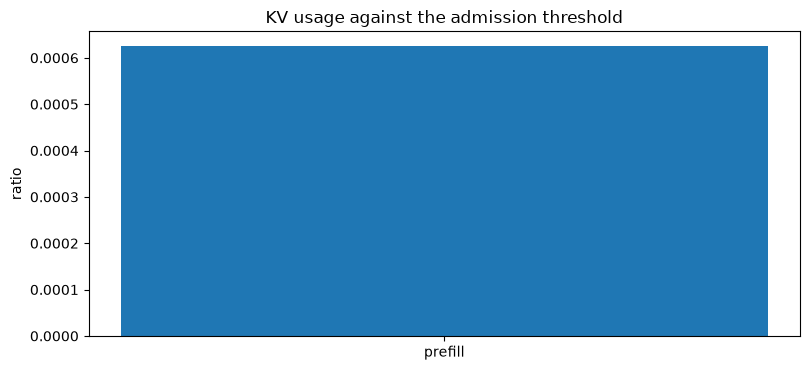

  how to read it: dashed line is the kv_threshold trigger

  >> Peak KV usage is 0.1% on an idle cluster, so nothing is scarce and the policy has nothing to decide. That is expected here. 02-capacity finds the load at which this crosses 90%, and until it does every admission arm would measure an inert component.



Report(title='Dodona 01 — cluster sanity', subtitle='go / no-go, no load', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='Does the cluster serve a real completion, and does it go THROUGH the control plane rather than past it?', note=''), _Block(kind='text', payload='Falsified by: orch_requests_total not moving, or a pool not answering', note=''), _Block(kind='heading', payload='The promises everything later is scored against', note=''), _Block(kind='table', payload=(['SLO', 'target', 'direction'], [['TTFT p95', '1.5s', 'max'], ['turn p95', '30s', 'max'], ['preemptions', '0', 'max'], ['shed rate at target load', '0.05', 'max'], ['concurrent sessions', 'derived in 02', 'min']]), note='From benchmarking/slos.py. The session target is derived in 02.'), _Block(kind='text', payload='Concurrency target not measured yet — run 02-capacity.', note=''), _Block(kind='heading', payload='1. Is anything listening?', note=''), _Block(kind='verdict', payload=

In [7]:
report.heading('6. Is anything scarce right now?')
kv = cluster.kv_usage()
report.table(['pool', 'kv_cache_usage_perc', 'vs 0.90'],
             [[p, f'{v:.4f}', 'below' if v < 0.90 else 'CROSSED'] for p, v in kv.items()])
report.bar('KV usage against the admission threshold', list(kv) or ['none'],
           {'kv_cache_usage_perc': [kv.get(p, 0) for p in (kv or ['none'])]},
           ylabel='ratio', hline=0.90,
           note='dashed line is the kv_threshold trigger')
peak = max(kv.values()) if kv else 0.0
report.conclusion(
    f'Peak KV usage is {peak:.1%} on an idle cluster, so nothing is scarce and '
    'the policy has nothing to decide. That is expected here. 02-capacity finds '
    'the load at which this crosses 90%, and until it does every admission arm '
    'would measure an inert component.')


## 7. How fast is a small request, and is it steady?

**Question.** Is latency stable, or does it drift as requests accumulate?

Ten sequential short requests, first discarded as warmup. A **flat** line is
healthy; a **rising** one means something accumulates per request — a leak, a
growing queue, or a cache being evicted and refilled.

Includes your tunnel round-trip, so read the shape and not the value.


In [8]:
report.heading('7. Latency on a small request')
lat = cluster.sample('Reply with the single word: ok', n=10, max_tokens=8)
if not lat:
    report.verdict(False, f'no samples — {cluster.last_error}')
    report.conclusion('Every sample failed, so there is no latency to report. '
                      'The error above is a gateway refusal, not a GPU limit.')
else:
    p50, p95 = percentile(lat, .5), percentile(lat, .95)
    report.table(['metric', 'seconds'], [
        ['n', len(lat)], ['min', f'{min(lat):.3f}'], ['p50', f'{p50:.3f}'],
        ['p95', f'{p95:.3f}'], ['max', f'{max(lat):.3f}']])
    report.line('Latency over ten sequential requests',
                list(range(1, len(lat) + 1)), {'seconds': lat},
                xlabel='request number', ylabel='seconds',
                hlines={f'p50 {p50:.3f}s': p50, f'p95 {p95:.3f}s': p95},
                note='flat is healthy; a rising line means something accumulates')
    drift = (lat[-1] - lat[0]) / max(lat[0], 1e-6)
    report.conclusion(
        f'p50 {p50:.3f}s, p95 {p95:.3f}s, spread {max(lat) - min(lat):.3f}s across ten '
        f'requests, drifting {drift:+.0%} end to end. '
        + ('Stable.' if abs(drift) < 0.25 else 'That drift is worth explaining.')
        + ' The tunnel is inside these numbers, so use make load to quote any.')



7. Latency on a small request


  FAIL  no samples — ConnectionResetError: [Errno 54] Connection reset by peer: 

  >> Every sample failed, so there is no latency to report. The error above is a gateway refusal, not a GPU limit.



## 8. Does decode pay for the prompt? — the decisive hop test

**Question.** Does latency grow with prompt length?

Decode is sent the full prompt either way. What differs:

- **blocks moved** → decode loads KV, so cost barely grows with length
- **no blocks** → decode re-prefills, so latency grows with length

Every prompt is made **unique**. With a shared prompt, calls 2..n are
prefix-cache hits on the decode pod and the line goes flat whether or not KV
ever moved — a false positive for exactly the claim under test. We measured
1.4x growth with shared prompts and 2.1x with unique ones.


In [9]:
report.heading('8. Does decode pay for the prompt?')
LENGTHS = [256, 1024, 4096, 8192, 12288]
points, dropped = [], []
for n_tok in LENGTHS:
    cluster.last_error = None
    s = cluster.sample(filler(n_tok) + '\n\nReply with the single word: ok',
                       n=3, max_tokens=8, warmup=1, unique=True)
    (points if s else dropped).append(
        (n_tok, percentile(s, .5)) if s else (n_tok, cluster.last_error or 'no samples'))

report.table(['prompt tokens', 'p50 seconds'],
             [[f'{n:,}', f'{v:.3f}'] for n, v in points])
report.verdict(not dropped, f'all {len(LENGTHS)} prompt lengths completed')
for n_tok, why in dropped:
    report.text(f'{n_tok:,} tokens DROPPED — {why}')

if len(points) >= 2:
    report.line('Latency against prompt length', [p[0] for p in points],
                {'p50 seconds': [p[1] for p in points]},
                xlabel='prompt tokens', ylabel='p50 seconds',
                note='rising = decode re-prefills; flat = the connector moved the blocks')
    growth = points[-1][1] / max(points[0][1], 1e-6)
    span   = points[-1][0] / max(points[0][0], 1)
    # span/4 was ~12x here, which nothing could fail. If blocks moved, decode
    # loads KV instead of computing it and the curve is near flat — so the
    # threshold has to be near 1, not a fraction of the span.
    report.verdict(growth < 1.2,
                   f'latency flat across prompt length ({growth:.1f}x for {span:.0f}x '
                   'more prompt) — flat is what moved blocks would look like')
    report.conclusion(
        f'From {points[0][0]:,} to {points[-1][0]:,} prompt tokens ({span:.0f}x), p50 went '
        f'{points[0][1]:.3f}s to {points[-1][1]:.3f}s ({growth:.1f}x). '
        + ('Decode is paying for the prompt, which agrees with section 5: no blocks moved.'
           if growth > 1.2 else
           'Nearly flat, which would mean decode is not recomputing — cross-check '
           'against section 5 before believing it.'))



8. Does decode pay for the prompt?


  prompt tokens  p50 seconds
  -------------  -----------
  FAIL  all 5 prompt lengths completed
  256 tokens DROPPED — ConnectionResetError: [Errno 54] Connection reset by peer: 
  1,024 tokens DROPPED — ConnectionResetError: [Errno 54] Connection reset by peer: 
  4,096 tokens DROPPED — ConnectionResetError: [Errno 54] Connection reset by peer: 
  8,192 tokens DROPPED — ConnectionResetError: [Errno 54] Connection reset by peer: 
  12,288 tokens DROPPED — ConnectionResetError: [Errno 54] Connection reset by peer: 


## 9. See it over time

Everything above is one scrape. These are the same metrics as series, which
is what separates a steady state from a spike you happened to catch.

Needs the tunnel and `make observability`. The Grafana password is printed
by that command.


In [10]:
report.heading('9. Grafana')
report.links([
    ('vLLM — KV, running/waiting, TTFT, prefix cache', grafana_dashboard('vllm')),
    ('Gateway — admit, shed, place, latency by stage',  grafana_dashboard('gateway')),
    ('Router — pick, sticky, KV hop',                   grafana_dashboard('router')),
    ('KEDA — scaler value against replicas',            grafana_dashboard('keda')),
    ('HAMi — device memory against the slice cap',      grafana_dashboard('hami')),
    ('explore: KV usage per pod',   grafana_explore('vllm:kv_cache_usage_perc')),
    ('explore: queue depth per pod', grafana_explore('vllm:num_requests_waiting')),
    ('explore: KV actually transferred',
     grafana_explore('vllm:external_prefix_cache_hits_total')),
])



9. Grafana


- [vLLM — KV, running/waiting, TTFT, prefix cache](http://127.0.0.1:31495/d/dodona-vllm?from=now-30m&to=now)
- [Gateway — admit, shed, place, latency by stage](http://127.0.0.1:31495/d/dodona-gateway?from=now-30m&to=now)
- [Router — pick, sticky, KV hop](http://127.0.0.1:31495/d/dodona-router?from=now-30m&to=now)
- [KEDA — scaler value against replicas](http://127.0.0.1:31495/d/dodona-keda?from=now-30m&to=now)
- [HAMi — device memory against the slice cap](http://127.0.0.1:31495/d/dodona-hami?from=now-30m&to=now)
- [explore: KV usage per pod](http://127.0.0.1:31495/explore?left=%7B%22datasource%22%3A%20%22Prometheus%22%2C%20%22queries%22%3A%20%5B%7B%22refId%22%3A%20%22A%22%2C%20%22expr%22%3A%20%22vllm%3Akv_cache_usage_perc%22%7D%5D%2C%20%22range%22%3A%20%7B%22from%22%3A%20%22now-30m%22%2C%20%22to%22%3A%20%22now%22%7D%7D)
- [explore: queue depth per pod](http://127.0.0.1:31495/explore?left=%7B%22datasource%22%3A%20%22Prometheus%22%2C%20%22queries%22%3A%20%5B%7B%22refId%22%3A%20%22A%22%2C%20%22expr%22%3A%20%22vllm%3Anum_requests_waiting%22%7D%5D%2C%20%22range%22%3A%20%7B%22from%22%3A%20%22now-30m%22%2C%20%22to%22%3A%20%22now%22%7D%7D)
- [explore: KV actually transferred](http://127.0.0.1:31495/explore?left=%7B%22datasource%22%3A%20%22Prometheus%22%2C%20%22queries%22%3A%20%5B%7B%22refId%22%3A%20%22A%22%2C%20%22expr%22%3A%20%22vllm%3Aexternal_prefix_cache_hits_total%22%7D%5D%2C%20%22range%22%3A%20%7B%22from%22%3A%20%22now-30m%22%2C%20%22to%22%3A%20%22now%22%7D%7D)

Report(title='Dodona 01 — cluster sanity', subtitle='go / no-go, no load', blocks=[_Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='Does the cluster serve a real completion, and does it go THROUGH the control plane rather than past it?', note=''), _Block(kind='text', payload='Falsified by: orch_requests_total not moving, or a pool not answering', note=''), _Block(kind='heading', payload='The promises everything later is scored against', note=''), _Block(kind='table', payload=(['SLO', 'target', 'direction'], [['TTFT p95', '1.5s', 'max'], ['turn p95', '30s', 'max'], ['preemptions', '0', 'max'], ['shed rate at target load', '0.05', 'max'], ['concurrent sessions', 'derived in 02', 'min']]), note='From benchmarking/slos.py. The session target is derived in 02.'), _Block(kind='text', payload='Concurrency target not measured yet — run 02-capacity.', note=''), _Block(kind='heading', payload='1. Is anything listening?', note=''), _Block(kind='verdict', payload=

## Save


In [11]:
# One file, overwritten. A timestamped PDF per run leaves a directory of
# near-identical files and no answer to 'which is current'. The run time is
# on the first page.
path  = report.save('01-sanity')
fails = report.failures()
print('wrote', path)
print()
if fails:
    print('NOT READY — these are open:')
    for f in fails:
        print('  -', f)
else:
    print('All checks passed. Next: 02-capacity')


wrote /Users/harshuljain/work/projects/experiments_and_courses/llm-inference/dodona/benchmarking/reports/01-sanity.pdf

NOT READY — these are open:
  - prefill emits 49.67 tokens per request (max_tokens=1 means ~1.0)
  - completion in 0.251s
  - the router RECORDED a hop
  - the connector has delivered at least one block
  - no samples — ConnectionResetError: [Errno 54] Connection reset by peer: 
  - all 5 prompt lengths completed
